
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [2]:
# 1.1 Импорт библиотек и загрузка данных
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("Human_Activity_Recognition_Using_Smartphones_Data - Human_Activity_Recognition_Using_Smartphones_Data.csv")

# 1.2 Размерность и типы данных
print("Размерность (строки, столбцы):", df.shape)
print("\nТипы данных (сколько столбцов каждого типа):")
print(df.dtypes.astype(str).value_counts())
print("\nНечисловой столбец (целевая переменная):", df.select_dtypes(exclude="number").columns.tolist())
print("\nКлассы Activity:")
print(df["Activity"].value_counts())

Размерность (строки, столбцы): (10299, 562)

Типы данных (сколько столбцов каждого типа):
float64    561
str          1
Name: count, dtype: int64

Нечисловой столбец (целевая переменная): ['Activity']

Классы Activity:
Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


In [3]:
# 1.3 Первые 5 строк и проверка пропусков
display(df.head())
print("Всего пропущенных значений:", df.isna().sum().sum())
print("Столбцов с пропусками:", (df.isna().sum() > 0).sum())

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


Всего пропущенных значений: 0
Столбцов с пропусками: 0



## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

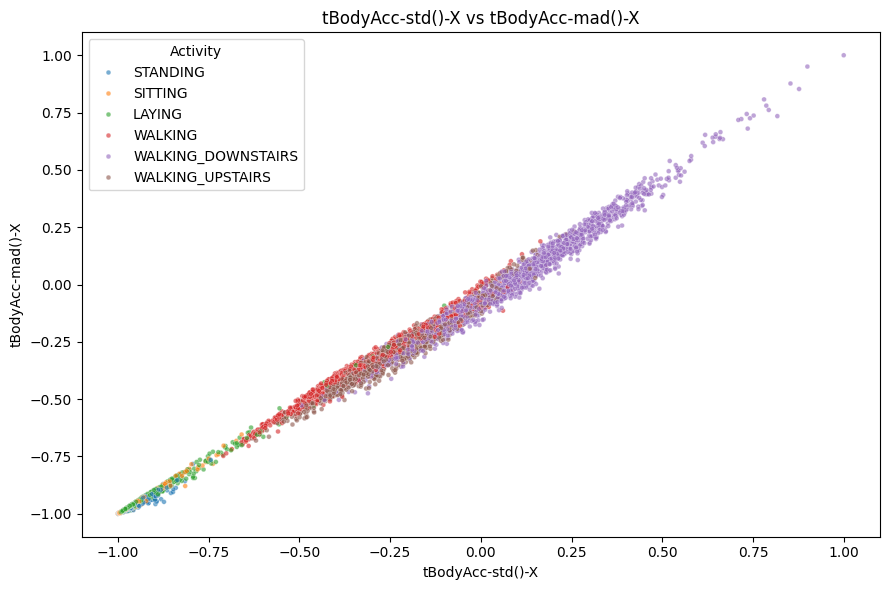

In [5]:
# 2.1 Scatter plot: связь двух числовых признаков
# std (стандартное отклонение) и mad (медианное абс. отклонение) ускорения по оси X
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="tBodyAcc-std()-X", y="tBodyAcc-mad()-X",
                hue="Activity", s=12, alpha=0.6)
plt.title("tBodyAcc-std()-X vs tBodyAcc-mad()-X")
plt.tight_layout()
plt.show()

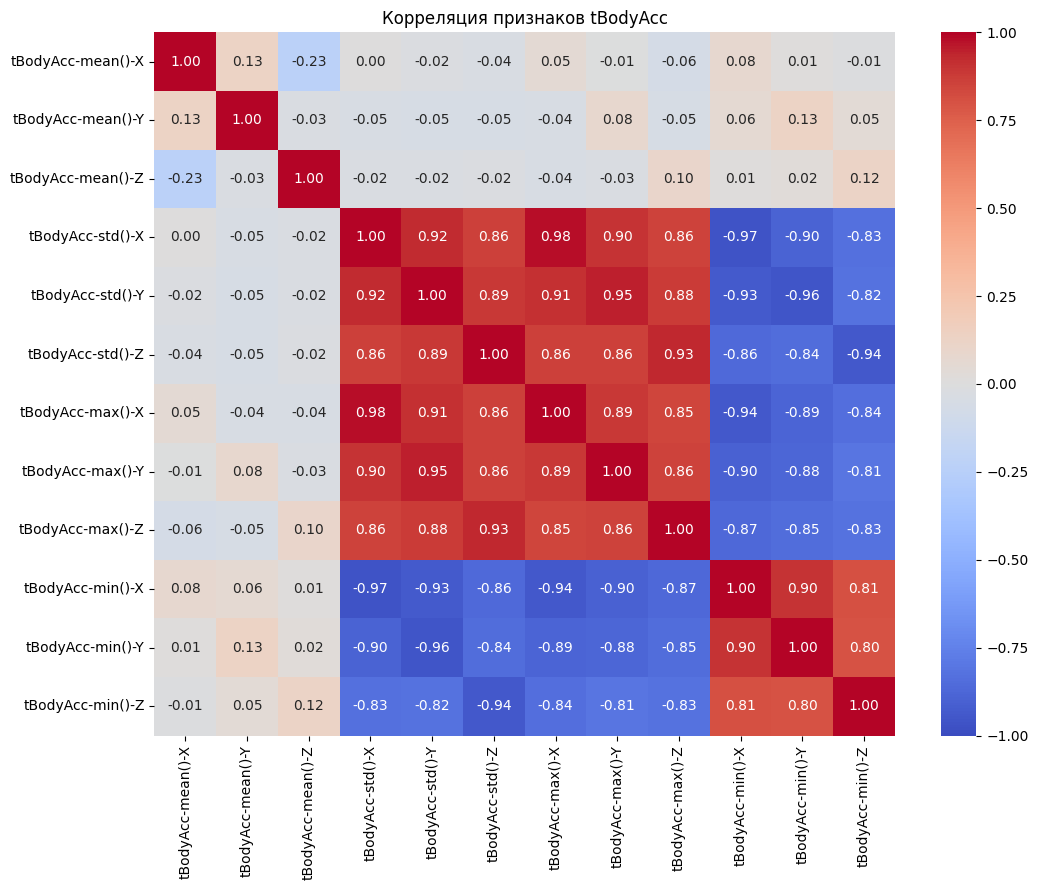

In [ ]:
# 2.2 Heatmap корреляций
# 12 признаков ускорения тела (mean / std / max / min по осям X, Y, Z)
cols = [c for c in df.columns if c.startswith("tBodyAcc-") and
        any(s in c for s in ["mean()", "std()", "max()", "min()"])]
corr = df[cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция признаков tBodyAcc")
plt.tight_layout()
plt.show()

Вывод признаки разброса (`std`, `max`) сильно коррелируют между собой (0.85–0.98), а с `min` — сильно отрицательно. Средние значения (`mean`) почти ни с чем не связаны. Значит, в данных много избыточных (мультиколлинеарных) признаков.

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Предсказать величину ускорения тела tBodyAccMag-mean()
# по 40 признакам ускорения tBodyAcc-*
reg_features = [c for c in df.columns if c.startswith("tBodyAcc-")]
X_reg = df[reg_features]
y_reg = df["tBodyAccMag-mean()"]

# 3.1 Разделение 80% / 20%
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)
print("Train:", Xr_train.shape, " Test:", Xr_test.shape)

# 3.2 Линейная регрессия
lin_reg = LinearRegression()
lin_reg.fit(Xr_train, yr_train)
yr_pred = lin_reg.predict(Xr_test)

# 3.3 Метрики ошибки
mae = mean_absolute_error(yr_test, yr_pred)
mse = mean_squared_error(yr_test, yr_pred)
rmse = np.sqrt(mse)
print(f"MAE  = {mae:.4f}")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"(для масштаба: целевая переменная лежит в [{y_reg.min():.2f}, {y_reg.max():.2f}], std = {y_reg.std():.3f})")

Train: (8239, 40)  Test: (2060, 40)
MAE  = 0.0079
MSE  = 0.0002
RMSE = 0.0128
(для масштаба: целевая переменная лежит в [-1.00, 1.00], std = 0.467)


- **MAE** — средняя абсолютная ошибка (в единицах целевой переменной): ≈ 0.008.
- **MSE** — средний квадрат ошибки, сильнее штрафует большие промахи: ≈ 0.0002.
- **RMSE** — корень из MSE, снова в исходных единицах: ≈ 0.013.

При разбросе целевой переменной std ≈ 0.47 ошибка очень мала — модуль ускорения хорошо выражается линейно через компоненты ускорения.


## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [ ]:
# 4.1 Импорт scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Предсказать Activity (6 классов) по 561 признаку
X = df.drop(columns="Activity")
y = df["Activity"]

# 4.2 Разделение 80% / 20% (stratify — сохраняем пропорции классов)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

# 4.3 cross_val_score для KNN (5 фолдов на обучающей выборке)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
scores = cross_val_score(knn, X_train, y_train, cv=5, scoring="accuracy")
print("Accuracy по фолдам:", np.round(scores, 4))
print(f"Средняя accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

# Финальная проверка на отложенной тестовой выборке
knn.fit(X_train, y_train)
print(f"Accuracy на тесте: {knn.score(X_test, y_test):.4f}")

Train: (8239, 561)  Test: (2060, 561)
Accuracy по фолдам: [0.9551 0.9563 0.9521 0.9593 0.9514]
Средняя accuracy: 0.9548 ± 0.0029
Accuracy на тесте: 0.9680


`cross_val_score` делит обучающую выборку на 5 частей, 5 раз обучает модель на 4 частях и проверяет на оставшейся. KNN даёт ≈ 95.5% ± 0.3% — результат стабилен между фолдами, а на тестовой выборке ≈ 96.8%. Масштабирование (`StandardScaler`) важно для KNN, т.к. он считает расстояния.


## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

In [ ]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, r2_score

# 5.1 Линейная регрессия
lin_reg = LinearRegression().fit(Xr_train, yr_train)
yr_pred = lin_reg.predict(Xr_test)
print(f"R² на тесте:   {r2_score(yr_test, yr_pred):.4f}")
print(f"RMSE на тесте: {np.sqrt(mean_squared_error(yr_test, yr_pred)):.4f}")

R² на тесте:   0.9992
RMSE на тесте: 0.0128


In [10]:
# 5.2 Логистическая регрессия — бинарная классификация
# Берём самую трудную пару классов: SITTING (0) vs STANDING (1)
mask = df["Activity"].isin(["SITTING", "STANDING"])
Xb = df.loc[mask].drop(columns="Activity")
yb = (df.loc[mask, "Activity"] == "STANDING").astype(int)

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.2, random_state=42, stratify=yb)

log_bin = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
log_bin.fit(Xb_train, yb_train)
yb_pred = log_bin.predict(Xb_test)

print(f"Accuracy: {accuracy_score(yb_test, yb_pred):.4f}")
print(classification_report(yb_test, yb_pred, target_names=["SITTING", "STANDING"]))

Accuracy: 0.9579
              precision    recall  f1-score   support

     SITTING       0.97      0.94      0.96       356
    STANDING       0.95      0.97      0.96       381

    accuracy                           0.96       737
   macro avg       0.96      0.96      0.96       737
weighted avg       0.96      0.96      0.96       737



In [11]:
# 5.3 SVM — классификация всех 6 видов активности
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale"))
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print(f"Accuracy SVM на тесте: {accuracy_score(y_test, y_pred_svm):.4f}")
print(classification_report(y_test, y_pred_svm))

Accuracy SVM на тесте: 0.9922
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.98      0.98       356
          STANDING       0.99      0.97      0.98       381
           WALKING       1.00      1.00      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      1.00      1.00       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060



1. **Линейная регрессия:** R² ≈ 0.999 — модель объясняет почти всю изменчивость целевой переменной.
2. **Логистическая регрессия (SITTING vs STANDING):** ≈ 95.8%. Это самая трудная пара классов — по датчикам телефона в кармане сидение и стояние похожи.
3. **SVM (6 классов, RBF-ядро):** ≈ 99.2% — лучшая одиночная модель; ошибается только между SITTING и STANDING.

## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

Accuracy логистической регрессии: 0.9859


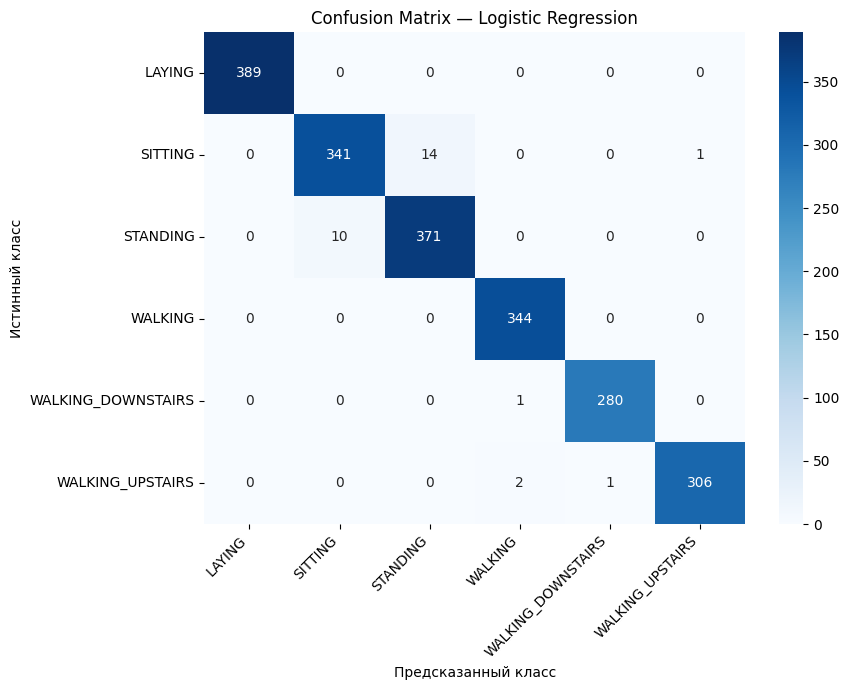

In [12]:
from sklearn.metrics import confusion_matrix

# 6.1 Логистическая классификация (мультикласс, 6 видов активности)
log_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
log_clf.fit(X_train, y_train)
y_pred_log = log_clf.predict(X_test)
print(f"Accuracy логистической регрессии: {accuracy_score(y_test, y_pred_log):.4f}")

# 6.2 Матрица ошибок + heatmap
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred_log, labels=labels)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Confusion Matrix — Logistic Regression")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

По диагонали — верные ответы, вне диагонали — ошибки. Почти все ошибки (24 из 29) — путаница SITTING ↔ STANDING. Классы движения и LAYING распознаются практически идеально.


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

θ (градиентный спуск) = 0.98927
θ (аналитически)      = 0.98927
J(θ) в конце          = 0.001576


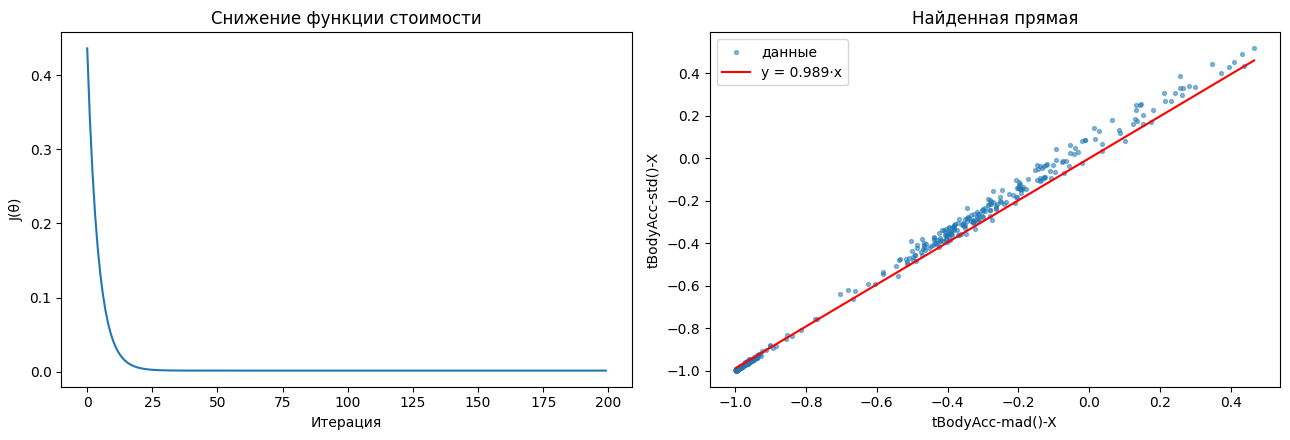

In [ ]:
sub = df.sample(500, random_state=42)
x_gd = sub["tBodyAcc-mad()-X"].values
y_gd = sub["tBodyAcc-std()-X"].values
n = len(x_gd)

def cost(theta):
    # средняя по выборке стоимость: J(θ) = (1/n) Σ (θx − y)²
    return np.mean((theta * x_gd - y_gd) ** 2)

def gradient(theta):
    # dJ/dθ = (2/n) Σ (θx − y)·x
    return 2 * np.mean((theta * x_gd - y_gd) * x_gd)

theta = 0.0          # начальное значение
lr = 0.1             # шаг обучения (learning rate)
history = []
for i in range(200):
    theta -= lr * gradient(theta)
    history.append(cost(theta))

# Проверка: точное аналитическое решение θ* = Σxy / Σx²
theta_exact = np.sum(x_gd * y_gd) / np.sum(x_gd ** 2)
print(f"θ (градиентный спуск) = {theta:.5f}")
print(f"θ (аналитически)      = {theta_exact:.5f}")
print(f"J(θ) в конце          = {history[-1]:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(history)
ax[0].set_xlabel("Итерация"); ax[0].set_ylabel("J(θ)")
ax[0].set_title("Снижение функции стоимости")
ax[1].scatter(x_gd, y_gd, s=8, alpha=0.5, label="данные")
xs = np.linspace(x_gd.min(), x_gd.max(), 100)
ax[1].plot(xs, theta * xs, color="red", label=f"y = {theta:.3f}·x")
ax[1].set_xlabel("tBodyAcc-mad()-X"); ax[1].set_ylabel("tBodyAcc-std()-X")
ax[1].set_title("Найденная прямая"); ax[1].legend()
plt.tight_layout()
plt.show()

На каждом шаге θ сдвигается против градиента: θ ← θ − lr·dJ/dθ, где dJ/dθ = 2·mean((θx − y)·x). Стоимость быстро падает и выходит на плато, а найденное θ ≈ 0.989 совпадает с аналитическим решением Σxy/Σx² — значит, реализация корректна.

## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


Accuracy Random Forest: 0.9820

Топ-10 важных признаков:
tGravityAcc-mean()-X      0.0346
tGravityAcc-min()-X       0.0295
angle(X,gravityMean)      0.0280
tGravityAcc-energy()-X    0.0267
tGravityAcc-mean()-Y      0.0251
tGravityAcc-min()-Y       0.0231
tGravityAcc-max()-X       0.0225
tGravityAcc-max()-Y       0.0191
angle(Y,gravityMean)      0.0170
tGravityAcc-energy()-Y    0.0126
dtype: float64


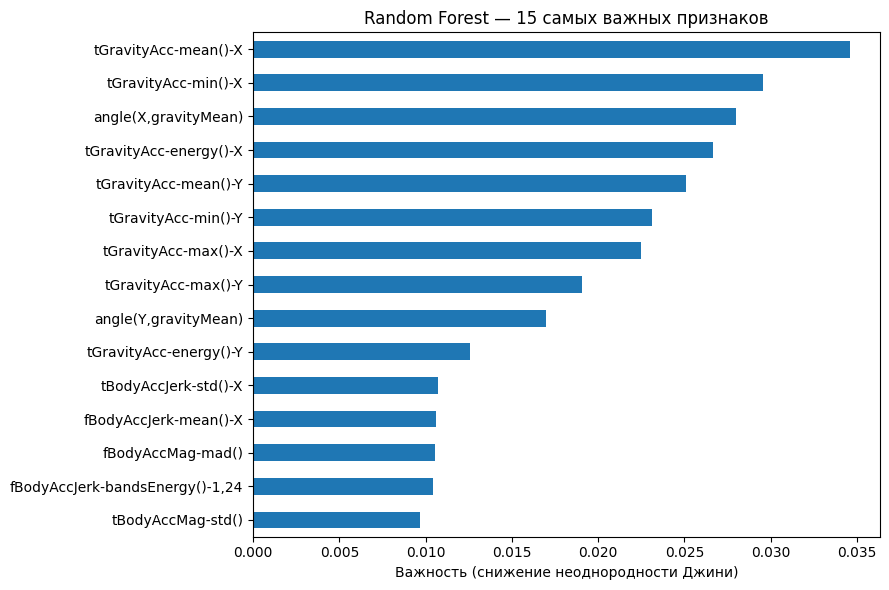

In [14]:
from sklearn.ensemble import RandomForestClassifier

# 8.3 Random Forest + важность признаков
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"Accuracy Random Forest: {accuracy_score(y_test, rf.predict(X_test)):.4f}")

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nТоп-10 важных признаков:")
print(importances.head(10).round(4))

plt.figure(figsize=(9, 6))
importances.head(15)[::-1].plot(kind="barh")
plt.xlabel("Важность (снижение неоднородности Джини)")
plt.title("Random Forest — 15 самых важных признаков")
plt.tight_layout()
plt.show()

Random Forest ≈ 98.2%. Самые важные признаки — связанные с гравитацией (`tGravityAcc-*`, `angle(X,gravityMean)`): они показывают ориентацию телефона в пространстве, а это главное, что отличает лежание, сидение и стояние.

AdaBoost  accuracy = 0.9743
Bagging   accuracy = 0.9675


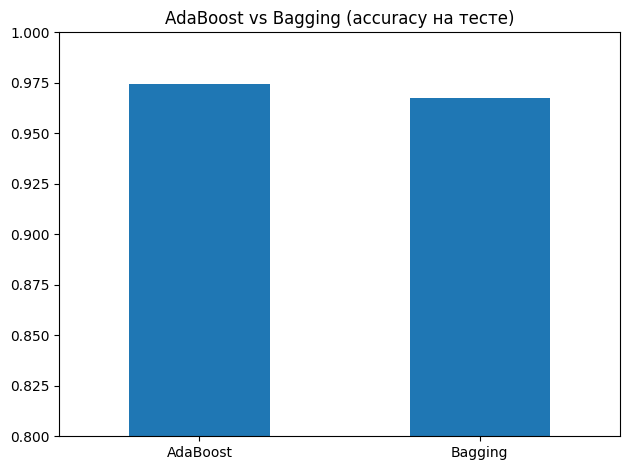

In [15]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# 8.4 Бустинг vs Бэггинг (базовая модель — решающее дерево)
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),
                         n_estimators=100, random_state=42)
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100, random_state=42, n_jobs=-1)

results = {}
for name, model in [("AdaBoost", ada), ("Bagging", bag)]:
    model.fit(X_train, y_train)
    results[name] = accuracy_score(y_test, model.predict(X_test))
    print(f"{name:9s} accuracy = {results[name]:.4f}")

pd.Series(results).plot(kind="bar", ylim=(0.8, 1.0), rot=0,
                        title="AdaBoost vs Bagging (accuracy на тесте)")
plt.tight_layout()
plt.show()

AdaBoost (≈ 97.4%) чуть лучше Bagging (≈ 96.8%).
- **Бэггинг** обучает много деревьев параллельно на случайных подвыборках и усредняет — снижает разброс (переобучение).
- **Бустинг** обучает деревья последовательно, каждое исправляет ошибки предыдущих — снижает смещение.

## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

In [17]:
from sklearn.ensemble import StackingClassifier

# 9.1 Базовые модели: Random Forest, SVM, логистическая регрессия
base_models = [
    ("rf",  RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ("svm", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, probability=True, random_state=42))),
    ("lr",  make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))),
]

# 9.2 Мета-модель — логистическая регрессия
stack = StackingClassifier(estimators=base_models,
                           final_estimator=LogisticRegression(max_iter=3000),
                           cv=5, n_jobs=-1)
stack.fit(X_train, y_train)

# 9.3 Итоговая точность на тесте
y_pred_stack = stack.predict(X_test)
print(f"Accuracy Stacking на тесте: {accuracy_score(y_test, y_pred_stack):.4f}")

Accuracy Stacking на тесте: 0.9942


Стекинг ≈ 99.4% — лучший результат в работе. Мета-модель (логистическая регрессия) учится на предсказаниях RF, SVM и LR и комбинирует их сильные стороны.

**Сводка по точности на тесте (6 классов):** KNN 96.8% · Bagging 96.8% · AdaBoost 97.4% · Random Forest 98.2% · Logistic Regression 98.6% · SVM 99.2% · **Stacking 99.4%**.


## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
